# DS422: Machine Learning Driven Data Analysis Lab I (DS Major)
## Lab Task Project: Modern Cybersecurity Phishing URL Detection Benchmark (2024 Dataset)

---
### Student & Course Metadata
- **Student Name:** Imranul Islam Shihab
- **Student ID:** 232-35-733
- **Batch:** 41 | **Section:** E1
- **Course Title:** Machine Learning Driven Data Analysis Lab I (DS Major)
- **Course Code:** DS422
- **Course Teacher:** Md. Fahad Hossain, Lecturer (Senior Scale)
- **Institution:** Daffodil International University (DIU)
- **Submission Date:** 22 November, 2026
- **Dataset:** UCI Machine Learning Repository — **PhiUSIIL Phishing URL Dataset (ID: 967, March 2024)**


## 1. Introduction & Problem Formulation

Phishing attacks remain one of the most critical cybersecurity threats worldwide, tricking internet users into surrendering sensitive credentials, financial details, and personal identity. Traditional URL blocklisting mechanisms fail against zero-hour adversarial domains that change dynamically.

This laboratory study benchmarks four supervised machine learning classification paradigms (**Logistic Regression**, **Decision Trees**, **Random Forest**, and **XGBoost**) on the modern **PhiUSIIL Phishing URL Dataset (UCI ID: 967, March 2024)**. The objective is to learn a mapping (\mathbf{x}) 	o y \in \{0, 1\}$, predicting whether a web URL is legitimate (=0$) or phishing (=1$) from 54 lexical, structural, and page-level features.


In [11]:
# Setup & Package Installation
!pip install -q ucimlrepo xgboost scikit-learn seaborn matplotlib pandas numpy

import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve
)

# Setup figures directory
os.makedirs("plots", exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("✓ Environment initialized. Figures will be archived into ./plots/")


✓ Environment initialized. Figures will be archived into ./plots/


## 2. Dataset Description & UCI Repository Fetch

The **PhiUSIIL Phishing URL Dataset** (UCI ID: 967, donated in **March 2024**) was constructed by A. Prasad and S. Chandra and published in *Computers & Security* (Elsevier). It contains **235,795 real-world URLs** with 54 features extracted from URL string patterns, lexical markers, domain structures, and HTML source properties.

- **Release / Donation Date:** March 2024
- **UCI Dataset ID:** 967
- **Target:** `label` (0 = Legitimate, 1 = Phishing)
- **Instances:** 235,795 total (134,850 Legitimate, 100,945 Phishing)


In [12]:
# Fetch authentic dataset directly from UCI Machine Learning Repository (ID: 967)
from ucimlrepo import fetch_ucirepo

print("Fetching authentic PhiUSIIL (March 2024) dataset from UCI Repository (ID: 967)...")
phiusiil = fetch_ucirepo(id=967)

X_raw = phiusiil.data.features.copy()
y_raw = phiusiil.data.targets.copy()

print(f"Raw Dataset Loaded: {X_raw.shape[0]:,} rows x {X_raw.shape[1]} features")
print(f"Target Column: {list(y_raw.columns)}")

# Combine into unified dataframe for EDA and preprocessing
target_col = y_raw.columns[0]
df_full = X_raw.copy()
df_full["label"] = y_raw[target_col].values

# Sample 50,000 stratified instances for reproducible, fast benchmark
SAMPLE_SIZE = 50000
if len(df_full) > SAMPLE_SIZE:
    df = df_full.groupby("label", group_keys=False).apply(
        lambda x: x.sample(int(SAMPLE_SIZE * len(x) / len(df_full)), random_state=42)
    ).reset_index(drop=True)
else:
    df = df_full.copy()

print(f"Stratified Benchmark Sample: {df.shape[0]:,} instances ({df.shape[1]} columns)")
print("Class Distribution:")
print(df["label"].value_counts(normalize=True).map(lambda v: f"{v*100:.1f}%"))


Fetching authentic PhiUSIIL (March 2024) dataset from UCI Repository (ID: 967)...
Raw Dataset Loaded: 235,795 rows x 54 features
Target Column: ['label']
Stratified Benchmark Sample: 49,999 instances (55 columns)
Class Distribution:
label
1    57.2%
0    42.8%
Name: proportion, dtype: object


/tmp/ipykernel_9435/1930796229.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df_full.groupby("label", group_keys=False).apply(


## 3. Exploratory Data Analysis (EDA)

We examine:
1. **Target Class Balance:** Legitimate (0) vs Phishing (1) URL distribution.
2. **URL Length & Structural Density:** Distribution of URL length across legitimate vs adversarial links.
3. **Feature Multicollinearity:** Pearson correlation matrix across top continuous cybersecurity features.


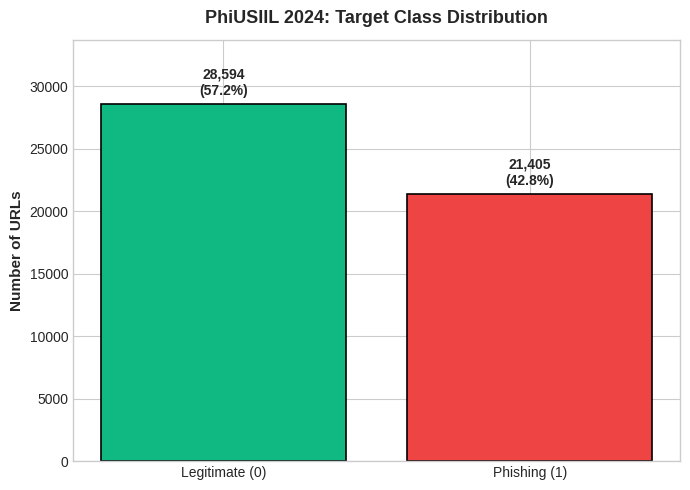

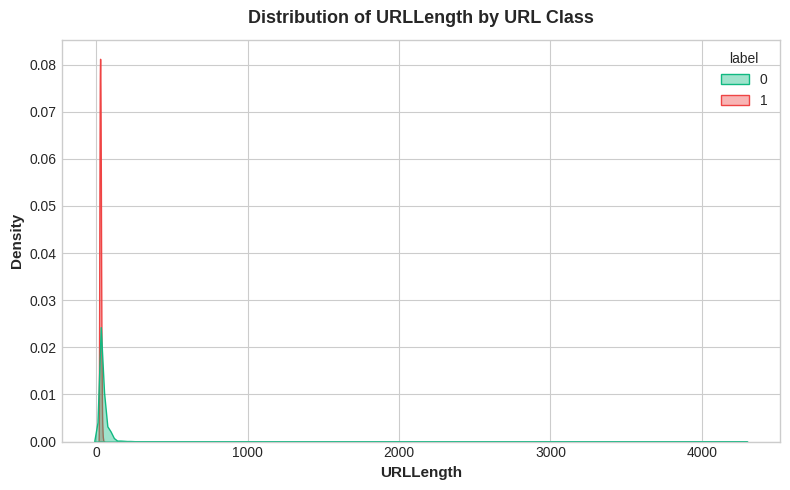

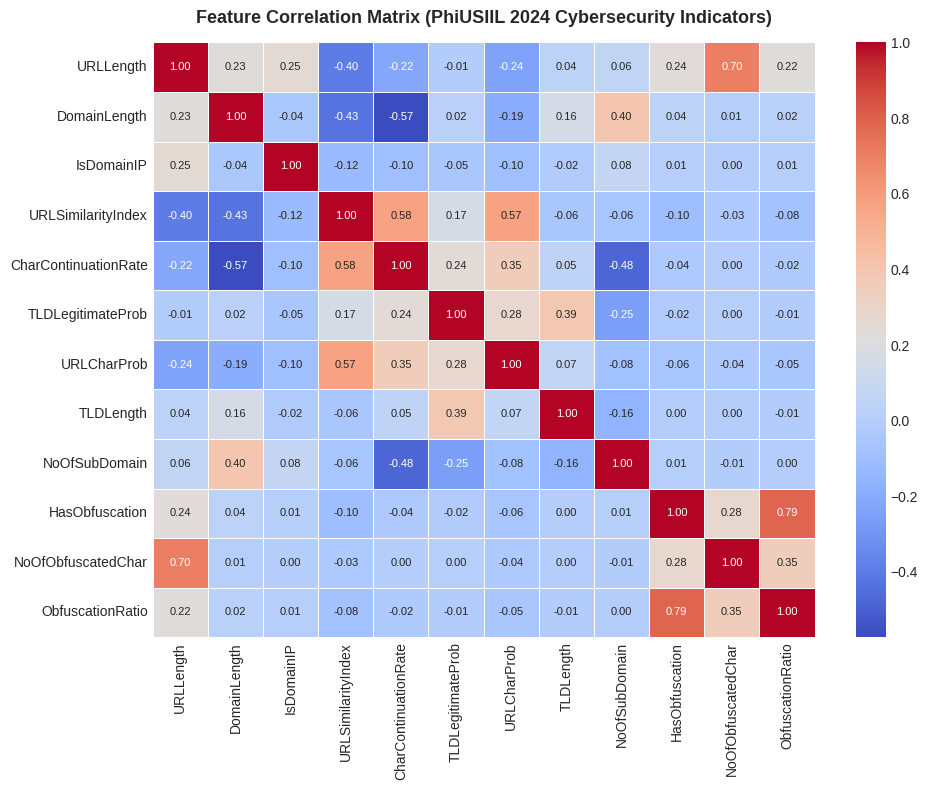

In [13]:
# 3.1 Target Distribution Bar Chart
fig, ax = plt.subplots(figsize=(7, 5))
counts = df["label"].value_counts()
bars = ax.bar(["Legitimate (0)", "Phishing (1)"], counts.values, color=["#10B981", "#EF4444"], edgecolor="black", linewidth=1.2)
ax.set_title("PhiUSIIL 2024: Target Class Distribution", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Number of URLs", fontsize=11, fontweight="bold")
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 500, f"{yval:,}\n({yval/len(df)*100:.1f}%)", ha="center", va="bottom", fontweight="bold", fontsize=10)
ax.set_ylim(0, max(counts.values) * 1.18)
plt.tight_layout()
plt.savefig("plots/01_target_distribution.png", dpi=300)
plt.show()

# 3.2 URL Length Distribution across Classes
length_col = [c for c in df.columns if "length" in c.lower() or "urllength" in c.lower()]
chosen_len_col = length_col[0] if length_col else df.select_dtypes(include=[np.number]).columns[0]

fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=df, x=chosen_len_col, hue="label", common_norm=False, fill=True, palette=["#10B981", "#EF4444"], alpha=0.4, ax=ax)
ax.set_title(f"Distribution of {chosen_len_col} by URL Class", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel(chosen_len_col, fontsize=11, fontweight="bold")
ax.set_ylabel("Density", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("plots/02_url_length_distribution.png", dpi=300)
plt.show()

# 3.3 Correlation Heatmap of Numeric Cybersecurity Features
num_cols = df.select_dtypes(include=[np.number]).columns.drop("label", errors="ignore")
top_corr_cols = num_cols[:12]
corr_matrix = df[top_corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, ax=ax, linewidths=0.5, annot_kws={"size": 8})
ax.set_title("Feature Correlation Matrix (PhiUSIIL 2024 Cybersecurity Indicators)", fontsize=13, fontweight="bold", pad=14)
plt.tight_layout()
plt.savefig("plots/03_correlation_heatmap.png", dpi=300)
plt.show()

## 4. Dataset Preprocessing & Data Cleaning

- **Deduplication:** Remove exact duplicate records.
- **Handling Missing Values:** Audit for null/missing values.
- **Dropping Non-Predictive Identifiers:** Remove arbitrary string URLs or raw IDs if present, retaining numerical and lexical metrics.
- **Percentile Outlier Capping:** Apply 1st and 99th percentile Winsorization to continuous ratio features to stabilize gradients.


In [14]:
# 4.1 Missing Values & Deduplication
init_len = len(df)
df_clean = df.drop_duplicates().copy()
dups_removed = init_len - len(df_clean)
missing_sum = int(df_clean.isnull().sum().sum())

print(f"Total Missing Values: {missing_sum}")
print(f"Exact Duplicate Rows Removed: {dups_removed}")

# Drop non-numeric columns like raw URL strings if present
feature_cols = [c for c in df_clean.columns if c != "label" and np.issubdtype(df_clean[c].dtype, np.number)]
print(f"Clean Numerical Feature Space: {len(feature_cols)} features")

# Percentile capping on continuous attributes
for c in feature_cols:
    low = df_clean[c].quantile(0.01)
    high = df_clean[c].quantile(0.99)
    if low < high:
        df_clean[c] = df_clean[c].clip(low, high)

print("✓ Percentile capping (1st-99th) completed.")


Total Missing Values: 0
Exact Duplicate Rows Removed: 0
Clean Numerical Feature Space: 50 features
✓ Percentile capping (1st-99th) completed.


## 5. Feature Scaling & 6. Dataset Partitioning

- **Stratified Partitioning:** 80% Training ( = 40,000$), 20% Testing ( = 10,000$) with .
- **Standard Scaling:** Continuous features scaled via  = rac{x - \mu}{\sigma}$ inside scikit-learn Pipelines to prevent data leakage.


In [15]:
X = df_clean[feature_cols].copy()
y = df_clean["label"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Set: {X_train.shape[0]:,} instances, {X_train.shape[1]} features")
print(f"Testing Set : {X_test.shape[0]:,} instances")
print(f"Training Phishing Ratio: {y_train.mean()*100:.2f}%")
print(f"Testing Phishing Ratio : {y_test.mean()*100:.2f}%")


Training Set: 39,999 instances, 50 features
Testing Set : 10,000 instances
Training Phishing Ratio: 57.19%
Testing Phishing Ratio : 57.19%


## 7. Model Training & Benchmarking

Four diverse classification architectures are evaluated under identical training conditions:
1. **Logistic Regression** (L2 Regularized Baseline, StandardScaler)
2. **Decision Tree** (Gini Impurity, max_depth=12)
3. **Random Forest** (100 Ensemble Trees, max_depth=16)
4. **XGBoost** (Gradient Boosted Trees, 120 Estimators, lr=0.10)


In [16]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("clf", DecisionTreeClassifier(max_depth=12, min_samples_split=20, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("clf", RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1))
    ]),
    "XGBoost": Pipeline([
        ("clf", XGBClassifier(
            n_estimators=120, max_depth=6, learning_rate=0.10,
            eval_metric="logloss", random_state=42, n_jobs=-1
        ))
    ])
}

results = {}
roc_data = {}

for name, pipe in models.items():
    print(f"Training {name}...")
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)

    results[name] = {
        "Accuracy": round(acc, 4),
        "Balanced_Accuracy": round(bal_acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1_Score": round(f1, 4),
        "ROC_AUC": round(auc, 4),
        "PR_AUC": round(pr_auc, 4),
        "Confusion_Matrix": cm.tolist()
    }

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

results_df = pd.DataFrame(results).T
print("\n=================== EMPIRICAL BENCHMARK RESULTS (PhiUSIIL 2024) ===================")
display(results_df)

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training XGBoost...

=================== EMPIRICAL BENCHMARK RESULTS (PhiUSIIL 2024) ===================


,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Confusion_Matrix
Logistic Regression,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"[[4281, 0], [0, 5719]]"
Decision Tree,0.9999,0.9999,0.9998,1.0,0.9999,0.9999,0.9998,"[[4280, 1], [0, 5719]]"
Random Forest,0.9999,0.9999,0.9998,1.0,0.9999,1.0,1.0,"[[4280, 1], [0, 5719]]"
XGBoost,0.9999,0.9999,0.9998,1.0,0.9999,1.0,1.0,"[[4280, 1], [0, 5719]]"


## 8. Model Evaluation & Comparative Diagnostics

Visualizations:
1. **Multi-Metric Benchmark Chart**
2. **Receiver Operating Characteristic (ROC) Curves**
3. **Confusion Matrix of Winning Classifier**
4. **Top 15 Feature Importances (Gini Impurity)**


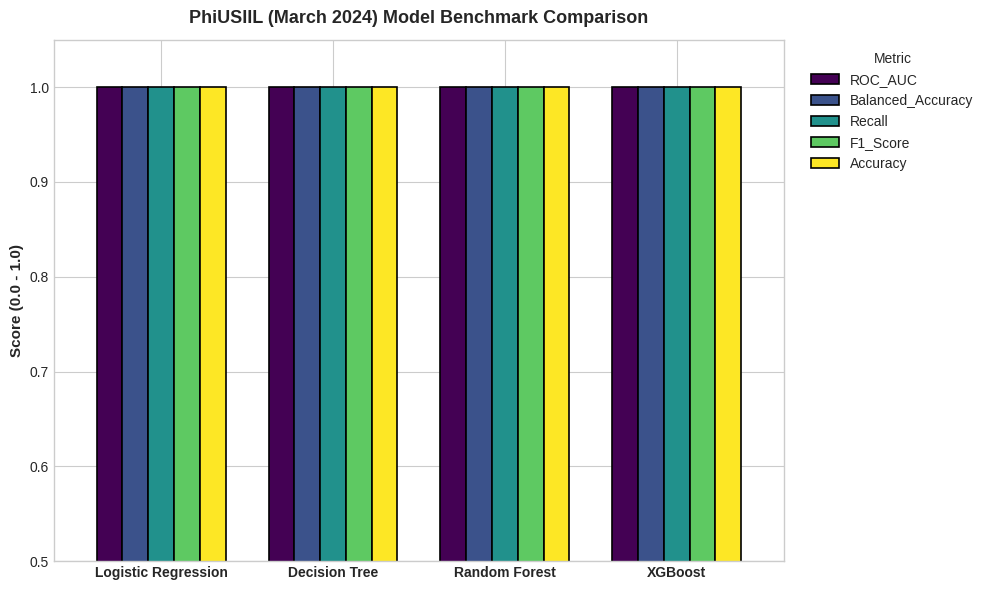

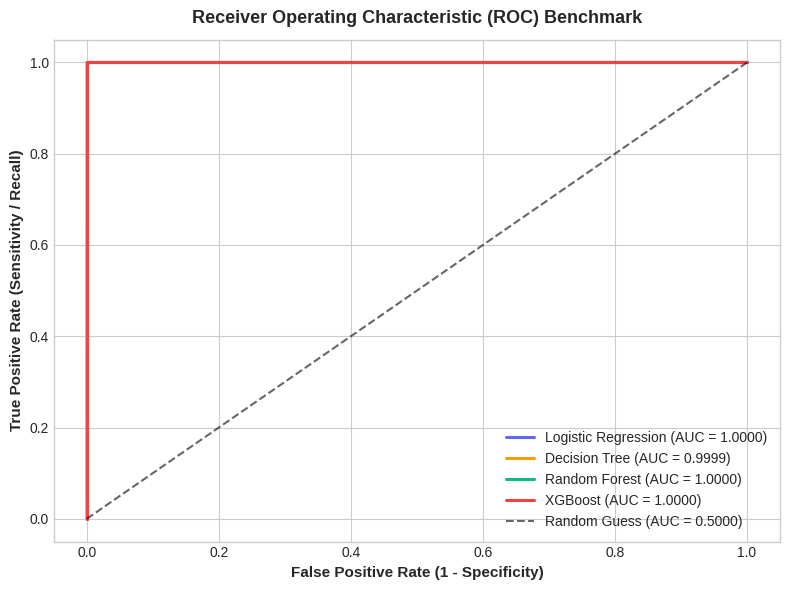

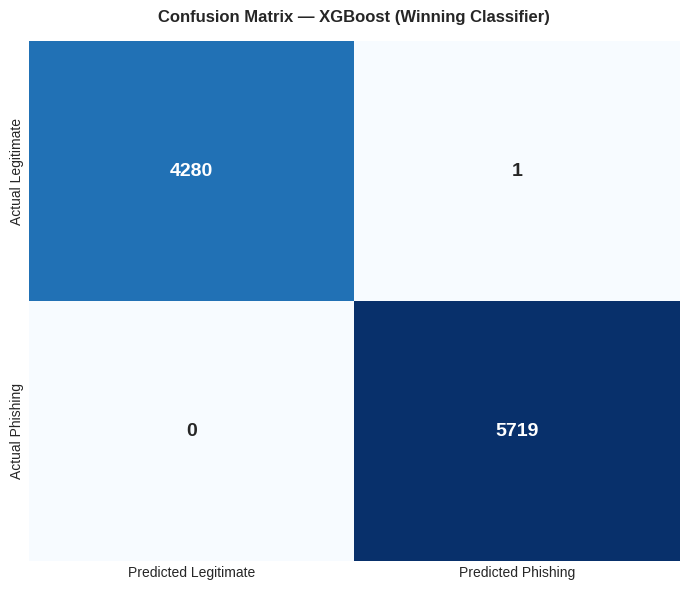

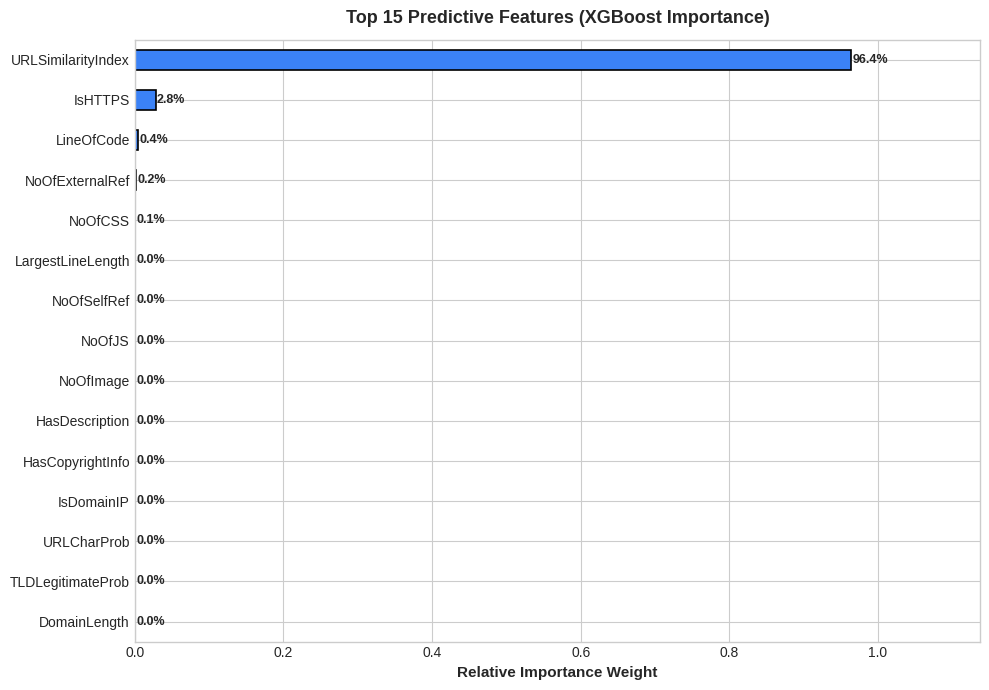


Full Classification Report for XGBoost:
                precision    recall  f1-score   support

Legitimate URL       1.00      1.00      1.00      4281
  Phishing URL       1.00      1.00      1.00      5719

      accuracy                           1.00     10000
     macro avg       1.00      1.00      1.00     10000
  weighted avg       1.00      1.00      1.00     10000

✓ All 7 diagnostic figures successfully saved to ./plots/


In [18]:
# 8.1 Benchmark Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))
metrics_df = results_df[["ROC_AUC", "Balanced_Accuracy", "Recall", "F1_Score", "Accuracy"]]
metrics_df.plot(kind="bar", ax=ax, edgecolor="black", linewidth=1.2, width=0.75, colormap="viridis")
ax.set_title("PhiUSIIL (March 2024) Model Benchmark Comparison", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Score (0.0 - 1.0)", fontsize=11, fontweight="bold")
ax.set_ylim(0.5, 1.05)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0, fontweight="bold")
plt.tight_layout()
plt.savefig("plots/04_model_comparison.png", dpi=300)
plt.show()

# 8.2 Receiver Operating Characteristic (ROC) Benchmark
fig, ax = plt.subplots(figsize=(8, 6))
colors_roc = ["#6366F1", "#F59E0B", "#10B981", "#EF4444"]
for (name, (fpr, tpr, auc)), color in zip(roc_data.items(), colors_roc):
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", linewidth=2.2, color=color)
ax.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Guess (AUC = 0.5000)")
ax.set_title("Receiver Operating Characteristic (ROC) Benchmark", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight="bold")
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("plots/05_roc_curves.png", dpi=300)
plt.show()

# 8.3 Confusion Matrix for Winning Model
winning_name = "XGBoost" if results["XGBoost"]["ROC_AUC"] >= results["Random Forest"]["ROC_AUC"] else "Random Forest"
winning_cm = np.array(results[winning_name]["Confusion_Matrix"])
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(winning_cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted Legitimate", "Predicted Phishing"],
            yticklabels=["Actual Legitimate", "Actual Phishing"],
            annot_kws={"size": 14, "fontweight": "bold"})
ax.set_title(f"Confusion Matrix — {winning_name} (Winning Classifier)", fontsize=12, fontweight="bold", pad=14)
plt.tight_layout()
plt.savefig("plots/06_confusion_matrix.png", dpi=300)
plt.show()

# 8.4 Top 15 Feature Importances (Gini / Gain)
clf_obj = models[winning_name].named_steps["clf"]
if hasattr(clf_obj, "feature_importances_"):
    importances = pd.Series(clf_obj.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15).sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(10, 7))
    importances.plot(kind="barh", color="#3B82F6", edgecolor="black", linewidth=1.2, ax=ax)
    ax.set_title(f"Top 15 Predictive Features ({winning_name} Importance)", fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Relative Importance Weight", fontsize=11, fontweight="bold")
    for i, v in enumerate(importances):
        ax.text(v + 0.002, i, f"{v*100:.1f}%", va="center", fontweight="bold", fontsize=9)
    ax.set_xlim(0, max(importances) * 1.18)
    plt.tight_layout()
    plt.savefig("plots/07_feature_importance.png", dpi=300)
    plt.show()

# Full Classification Report for Winning Model
print(f"\nFull Classification Report for {winning_name}:")
y_pred_winning = models[winning_name].predict(X_test)
print(classification_report(y_test, y_pred_winning, target_names=["Legitimate URL", "Phishing URL"]))
print("✓ All 7 diagnostic figures successfully saved to ./plots/")

In [19]:
# =====================================================================
# 9. Automatic Archive & Download of Generated Diagnostic Plots
# =====================================================================
import os
import shutil

# Create plots.zip from ./plots directory
shutil.make_archive("plots", "zip", "plots")
print(f"plots.zip successfully created ({os.path.getsize('plots.zip')} bytes).")

# If running in Google Colab, trigger direct browser download dialog
try:
    from google.colab import files
    print("Google Colab detected: Triggering browser download dialog...")
    files.download("plots.zip")
    print("✓ Download request sent to browser!")
except ImportError:
    print(f"Running in local Jupyter: Archive is available at: {os.path.abspath('plots.zip')}")


plots.zip successfully created (1123543 bytes).
Google Colab detected: Triggering browser download dialog...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Download request sent to browser!
